# Notebook 02 — Equilibrium vs. Scheil solidification of Al–Zn alloys

**Goal:** predict *how* three Al–Zn alloys freeze — the solid fraction as a function of temperature — under two idealised limits, and use the difference to understand **microsegregation**. At the end there is a clearly marked section where you add **your own measured solidification data** for comparison.

**What you will learn**

1. The two textbook limits of solidification: **equilibrium (lever rule)** and **Scheil–Gulliver**.
2. How to run both with the [`scheil`](https://github.com/pycalphad/scheil) package on top of pycalphad.
3. How to read solid-fraction curves, freezing ranges and the amount of non-equilibrium eutectic.
4. Why Scheil predicts *cored* dendrites (composition gradients inside each grain) — i.e. microsegregation.

> Run **Notebook 01** first if you haven't: it introduces the database, the phases, and the wt.% ↔ mole-fraction conversion.

---

### 📚 Sources to cite

* **Database:** S. an Mey, *Z. Metallkd.* **84** (1993) 451–455 (TDB file by T. Abe, K. Hashimoto, Y. Sawada, NIMS CPDDB), obtained from pycalphad's open example databases: [`examples/databases/alzn_mey.tdb`](https://github.com/pycalphad/pycalphad/blob/develop/examples/databases/alzn_mey.tdb).
* **pycalphad:** R. Otis & Z.-K. Liu, *J. Open Res. Softw.* **5** (2017) 1, doi:[10.5334/jors.140](https://doi.org/10.5334/jors.140).
* **scheil package:** B. Bocklund *et al.*, *"Experimental validation of Scheil–Gulliver simulations for gradient path planning in additively manufactured functionally graded materials"*, *Materials Today Communications* **25** (2020) 101515, doi:[10.1016/j.mtcomm.2020.101515](https://doi.org/10.1016/j.mtcomm.2020.101515).
* **Classic theory:** E. Scheil, *Z. Metallkd.* **34** (1942) 70; G. H. Gulliver, *J. Inst. Met.* **9** (1913) 120.

## 1. The physics in one picture: two limits of solidification

When an alloy freezes, the first solid that forms has a *different composition* from the liquid (Notebook 01, Section 3: in Al–Zn the solid is **poorer in Zn**, so Zn is pushed into the liquid). What happens next depends on how fast atoms can **diffuse**, compared with how fast the alloy is cooled.

| | **Equilibrium (lever rule)** | **Scheil–Gulliver** |
|---|---|---|
| Diffusion in the **liquid** | complete (liquid is always uniform) | complete (liquid is always uniform) |
| Diffusion in the **solid** | **complete** — the whole solid continually re-adjusts to the equilibrium composition | **zero** — once a layer of solid forms, its composition is frozen in |
| Interface | local equilibrium | local equilibrium |
| Physical picture | infinitely slow cooling | fast-ish cooling, slow solid diffusion (typical castings, welds, AM) |
| Result | solid ends up **homogeneous** at the alloy composition; solidification ends at the **solidus** | solid is **cored** (composition gradient); liquid keeps enriching in Zn and can reach the **eutectic** |

Real castings sit **between** these limits (some "back-diffusion" in the solid happens), but usually much closer to Scheil — which is why industry uses Scheil calculations constantly (hot-tearing susceptibility, incipient-melting temperature for heat treatment, castability, additive manufacturing).

**How the `scheil` package works:** it steps the temperature down by a small amount; at each step it computes the equilibrium between the *remaining liquid* and solid, "locks away" the solid formed in that step, and makes the new remaining liquid the starting composition for the next step. Repeat until (almost) no liquid is left.

## 2. Setup

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pycalphad import Database, binplot
from pycalphad import variables as v

# The scheil package (pip install scheil) builds on pycalphad
from scheil import simulate_scheil_solidification, simulate_equilibrium_solidification

# Hide harmless NumPy DeprecationWarnings raised inside pycalphad/scheil
warnings.filterwarnings("ignore", category=DeprecationWarning)

# ---- Database & system definition (same as Notebook 01) -------------------
DB_PATH    = "../databases/alzn_mey.tdb"
db         = Database(DB_PATH)
COMPONENTS = ["AL", "ZN", "VA"]          # always include VA (vacancies)
PHASES     = list(db.phases.keys())      # LIQUID, FCC_A1, HCP_A3
LIQUID     = "LIQUID"                    # name of the liquid phase in this TDB

# ---- Unit helpers ----------------------------------------------------------
M_AL, M_ZN = 26.9815, 65.38              # g/mol

def wt_to_x_zn(wt_pct_zn):
    # wt.% Zn -> mole fraction Zn
    w = np.asarray(wt_pct_zn, dtype=float) / 100.0
    return (w / M_ZN) / (w / M_ZN + (1 - w) / M_AL)

def x_to_wt_zn(x_zn):
    # mole fraction Zn -> wt.% Zn
    x = np.asarray(x_zn, dtype=float)
    return 100.0 * x * M_ZN / (x * M_ZN + (1 - x) * M_AL)

def K_to_C(T):
    return np.asarray(T, dtype=float) - 273.15

os.makedirs("../figures", exist_ok=True)

# Colour-blind-friendly colours (Okabe–Ito palette), one per alloy
COLORS = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9"]

## 3. Choose the alloys

We pick three Al-rich compositions that span "dilute" to "concentrated". They're given in **wt.%** (how you'd weigh them out in the lab) and converted to mole fraction for the calculation.

✏️ *You can change this list — e.g. to match the alloys you cast in the lab.*

In [2]:
# label -> wt.% Zn
ALLOYS = {
    "Al-10Zn": 10.0,
    "Al-30Zn": 30.0,
    "Al-50Zn": 50.0,
}

for label, wt in ALLOYS.items():
    print(f"{label}:  {wt:4.1f} wt.% Zn  ->  X(Zn) = {wt_to_x_zn(wt):.4f}")

Al-10Zn:  10.0 wt.% Zn  ->  X(Zn) = 0.0438
Al-30Zn:  30.0 wt.% Zn  ->  X(Zn) = 0.1503
Al-50Zn:  50.0 wt.% Zn  ->  X(Zn) = 0.2921


## 4. Run the simulations

`run_solidification()` below wraps both `scheil` functions. Important arguments:

* `composition` – dict of mole fractions, e.g. `{v.X('ZN'): 0.044}`
* `start_temperature` – must be **above the liquidus** (950 K is above pure Al's melting point, 933 K, so it's safe for every Al–Zn alloy)
* `step_temperature` – temperature step in K. 1 K is a good default; the Scheil routine also refines steps adaptively near phase changes.

Both functions return a `SolidificationResult` with, among others:

* `.temperatures` – list of temperatures (K)
* `.fraction_solid` – solid fraction at each temperature
* `.cum_phase_amounts[phase]` – cumulative amount of each solid phase
* `.phase_compositions[phase][element]` – composition of each phase *at each step* (for Scheil, the solid entry is the composition of the solid **forming at that instant**)

We cache results in a dictionary so that the lab-data section can reuse them. Expect ~5 s per alloy.

In [3]:
START_T = 950.0   # K  (above the liquidus of every Al-Zn alloy)
STEP_T  = 1.0     # K

_cache = {}       # wt.% -> results (so we never compute the same alloy twice)

def run_solidification(wt_pct_zn):
    # Run equilibrium AND Scheil solidification for one alloy (wt.% Zn).
    key = round(float(wt_pct_zn), 3)
    if key in _cache:
        return _cache[key]

    comp = {v.X("ZN"): float(wt_to_x_zn(wt_pct_zn))}

    sch = simulate_scheil_solidification(
        db, COMPONENTS, PHASES, comp, START_T,
        step_temperature=STEP_T, liquid_phase_name=LIQUID)

    eqm = simulate_equilibrium_solidification(
        db, COMPONENTS, PHASES, comp, START_T,
        step_temperature=STEP_T, liquid_phase_name=LIQUID)

    _cache[key] = {"scheil": sch, "equilibrium": eqm}
    return _cache[key]

results = {}
for label, wt in ALLOYS.items():
    print(f"Simulating {label} ...", end=" ", flush=True)
    results[label] = run_solidification(wt)
    print("done")

Simulating Al-10Zn ... 

done
Simulating Al-30Zn ... 

done
Simulating Al-50Zn ... 

done


## 5. Solid fraction vs. temperature

This is *the* key plot. For each alloy: **solid line = equilibrium**, **dashed line = Scheil**, same colour.

We plot temperature in **°C** because that's what thermocouples in the lab read.

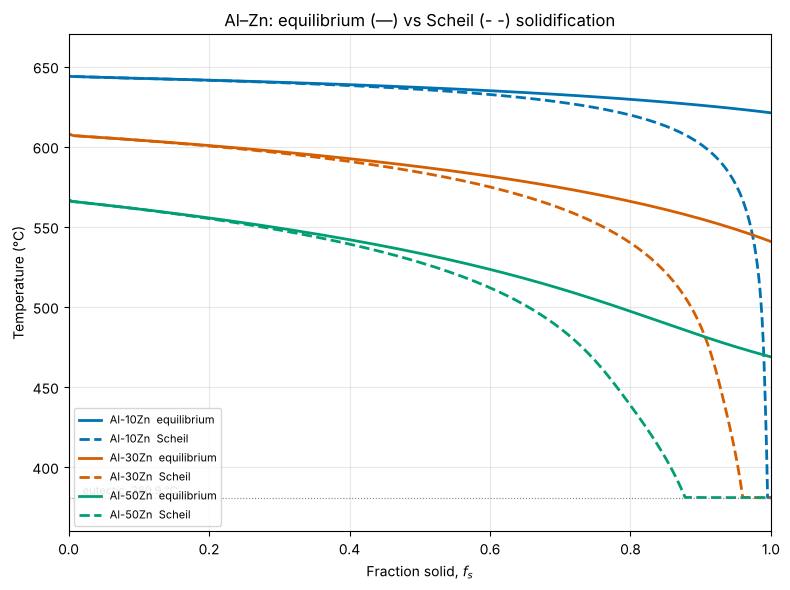

In [4]:
def plot_fs_curves(ax, labels=None):
    # Draw equilibrium (solid) and Scheil (dashed) f_s(T) curves on `ax`.
    labels = labels or list(ALLOYS)
    for i, label in enumerate(labels):
        c = COLORS[i % len(COLORS)]
        r = run_solidification(ALLOYS[label])
        eqm, sch = r["equilibrium"], r["scheil"]
        ax.plot(eqm.fraction_solid, K_to_C(eqm.temperatures), "-",  color=c, lw=2,
                label=f"{label}  equilibrium")
        ax.plot(sch.fraction_solid, K_to_C(sch.temperatures), "--", color=c, lw=2,
                label=f"{label}  Scheil")
    ax.axhline(380.9, color="grey", lw=0.8, ls=":")
    ax.text(0.02, 383, "eutectic, 380.9 °C", color="grey", fontsize=8)
    ax.set_xlabel("Fraction solid, $f_s$")
    ax.set_ylabel("Temperature (°C)")
    ax.set_xlim(0, 1.0)
    ax.grid(alpha=0.3)

fig, ax = plt.subplots(figsize=(8, 6))
plot_fs_curves(ax)
ax.set_ylim(360, 670)
ax.set_title("Al–Zn: equilibrium (—) vs Scheil (- -) solidification")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig("../figures/fraction_solid_vs_T.png", dpi=200)
plt.show()

### Numbers worth reporting

The table below extracts the characteristic temperatures:

* **Liquidus** – first solid appears (identical for both models — the very first solid doesn't know about diffusion yet).
* **Equilibrium solidus** – lever-rule end of solidification.
* **Scheil end** – where the Scheil calculation runs out of liquid. If this equals the eutectic temperature, the last liquid froze as a **eutectic** (FCC + HCP).
* **Freezing range** – liquidus minus end temperature. A wide freezing range means a long "mushy zone": more microsegregation, more shrinkage porosity, higher hot-tearing risk.
* **Scheil eutectic fraction** – fraction of the alloy that's still liquid when the eutectic temperature is reached, i.e. the amount of *non-equilibrium* eutectic that ends up between the dendrites.

In [5]:
def summarise(label, wt):
    r = run_solidification(wt)
    eqm, sch = r["equilibrium"], r["scheil"]
    T_eq, fs_eq = np.array(eqm.temperatures), np.array(eqm.fraction_solid)
    T_s,  fs_s  = np.array(sch.temperatures), np.array(sch.fraction_solid)

    T_liq = T_s[np.argmax(fs_s > 0)]           # first temperature with any solid
    T_sol_eq = T_eq[-1]                        # equilibrium: last step = solidus
    T_end_s = T_s[-1]                          # Scheil: last step

    # Scheil: the final step is the eutectic reaction. The liquid left just
    # before it (1 - f_s at the second-to-last step) all becomes eutectic.
    reaches_eutectic = abs(T_end_s - 654.0) < 1.0
    f_eut = (1 - fs_s[-2]) if reaches_eutectic else 0.0

    return {
        "alloy": label, "wt.% Zn": wt, "X(Zn)": round(float(wt_to_x_zn(wt)), 4),
        "liquidus (°C)": round(K_to_C(T_liq).item(), 1),
        "eq. solidus (°C)": round(K_to_C(T_sol_eq).item(), 1),
        "Scheil end (°C)": round(K_to_C(T_end_s).item(), 1),
        "eq. freezing range (K)": round(T_liq - T_sol_eq, 1),
        "Scheil freezing range (K)": round(T_liq - T_end_s, 1),
        "Scheil eutectic fraction": round(f_eut, 4),
    }

summary = pd.DataFrame([summarise(l, w) for l, w in ALLOYS.items()]).set_index("alloy")
summary

,wt.% Zn,X(Zn),liquidus (°C),eq. solidus (°C),Scheil end (°C),eq. freezing range (K),Scheil freezing range (K),Scheil eutectic fraction
alloy,,,,,,,,
Al-10Zn,10.0,0.0438,642.9,621.1,380.8,21.8,262.0,0.0049
Al-30Zn,30.0,0.1503,606.9,540.7,380.8,66.1,226.0,0.0402
Al-50Zn,50.0,0.2921,565.9,468.7,380.8,97.1,185.0,0.1222


**Reading the results**

1. **All three alloys are single-phase FCC at equilibrium** (their equilibrium solidus is far above the eutectic; check the phase diagram in Notebook 01). The lever rule says they should finish freezing roughly 90–240 K above 381 °C, as homogeneous solid solutions.
2. **Scheil predicts every alloy keeps a little liquid all the way down to the eutectic at 380.9 °C.** The freezing range grows dramatically — about 2× for Al‑50Zn and more than 10× for Al‑10Zn, whose equilibrium freezing range is only ~22 K. That last liquid freezes as an FCC + HCP eutectic network between the dendrites — a phase that "shouldn't be there" according to the equilibrium diagram. This is *non-equilibrium eutectic*, a classic microsegregation signature you can see in an optical micrograph.
3. **The more Zn, the more eutectic** — but even 10 wt.% Zn gives a non-zero amount.
4. **Practical consequences:**
   * *Heat treatment:* if you solution-treat a Scheil-solidified casting above 381 °C, the Zn-rich interdendritic regions can **melt locally (incipient melting)** even though the equilibrium solidus is much higher. That's why homogenisation schedules start low and ramp up.
   * *Hot tearing:* a long tail of liquid at high f<sub>s</sub> (f<sub>s</sub> > 0.9) means the solid network is weak while it is still being pulled by thermal contraction.

## 6. Where does the liquid go? Plotting the solidification path on the phase diagram

In Scheil solidification, the *remaining liquid* slides down the liquidus line, getting richer in Zn, until it hits the eutectic point. Let's overlay that path on the diagram. (The short vertical segments at the top are the fully liquid alloy cooling at constant composition until it reaches the liquidus; the dotted lines mark each alloy's nominal composition.)

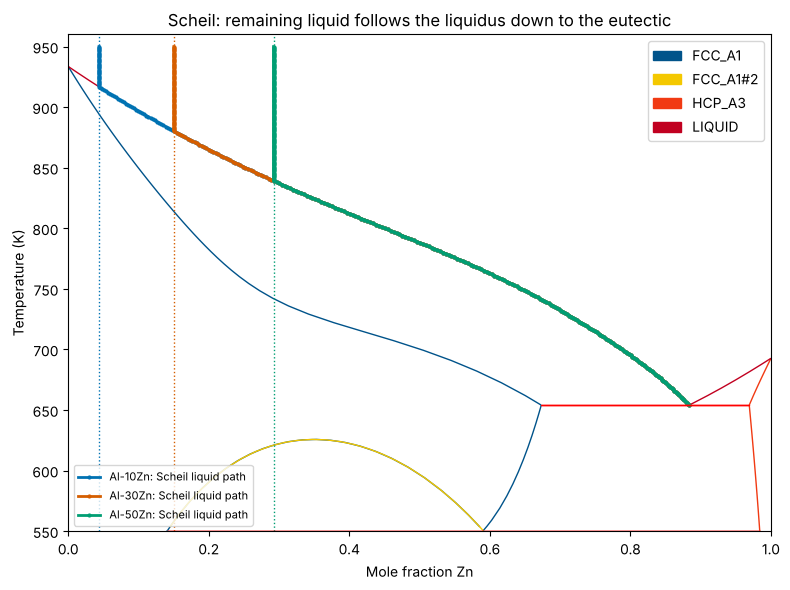

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))
binplot(db, COMPONENTS, PHASES,
        {v.N: 1, v.P: 101325, v.T: (550, 960, 10), v.X("ZN"): (0, 1, 0.02)},
        plot_kwargs={"ax": ax, "tielines": False})

for i, (label, wt) in enumerate(ALLOYS.items()):
    sch = results[label]["scheil"]
    x_liq = np.array(sch.x_liquid["ZN"])           # liquid composition each step
    T = np.array(sch.temperatures)
    ok = np.isfinite(x_liq)                         # NaN once liquid is gone
    ax.plot(x_liq[ok], T[ok], "-o", ms=2, color=COLORS[i], lw=2,
            label=f"{label}: Scheil liquid path")
    ax.axvline(wt_to_x_zn(wt), color=COLORS[i], ls=":", lw=1)   # nominal alloy

ax.set_ylim(550, 960)
ax.set_title("Scheil: remaining liquid follows the liquidus down to the eutectic")
ax.set_xlabel("Mole fraction Zn")
ax.set_ylabel("Temperature (K)")
# Put our labels in a second legend so binplot's phase legend is kept
handles = [h for h in ax.get_lines() if h.get_label().endswith("liquid path")]
phase_legend = ax.get_legend()
phase_legend.set_loc("upper right")          # move binplot's legend inside the axes
phase_legend.set_bbox_to_anchor((1.0, 1.0))
ax.add_artist(phase_legend)
ax.legend(handles=handles, loc="lower left", fontsize=8)
fig.tight_layout()
fig.savefig("../figures/scheil_liquid_path.png", dpi=200)
plt.show()

## 7. Microsegregation inside a dendrite ("coring")

Because Scheil assumes **no diffusion in the solid**, every layer of solid keeps the composition it had when it formed. The very first solid (the dendrite **core**, f<sub>s</sub> ≈ 0) is Zn-poor; the last solid (the **interdendritic** region, f<sub>s</sub> → 1) is Zn-rich.

So if we plot *the composition of the solid formed* versus *the fraction solid at which it formed*, we get a prediction of the **concentration profile from the centre of a dendrite arm to its edge** — something you could measure with EDS/EPMA line scans across a dendrite.

Under the equilibrium assumption the final solid is uniform — a flat line at the alloy composition (dotted).

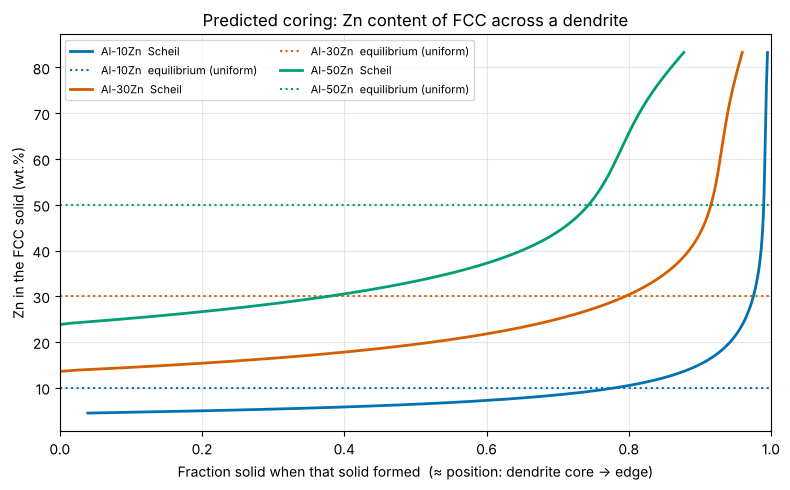

Al-10Zn: first FCC (core) =   4.5 wt.% Zn,  last FCC (edge) =  83.3 wt.% Zn
Al-30Zn: first FCC (core) =  13.6 wt.% Zn,  last FCC (edge) =  83.3 wt.% Zn
Al-50Zn: first FCC (core) =  23.9 wt.% Zn,  last FCC (edge) =  83.3 wt.% Zn


In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
for i, (label, wt) in enumerate(ALLOYS.items()):
    sch = results[label]["scheil"]
    fs   = np.array(sch.fraction_solid)
    x_s  = np.array(sch.phase_compositions["FCC_A1"]["ZN"])  # FCC forming at each step
    # The solid formed during step i fills the interval fs[i-1] -> fs[i], so we
    # plot its composition at the midpoint of that interval.
    fs_mid = 0.5 * (np.concatenate([[0.0], fs[:-1]]) + fs)
    ok = np.isfinite(x_s) & (fs < 1.0)       # skip the 'no solid yet' and eutectic steps
    ax.plot(fs_mid[ok], x_to_wt_zn(x_s[ok]), "-", color=COLORS[i], lw=2, label=f"{label}  Scheil")
    ax.axhline(wt, color=COLORS[i], ls=":", lw=1.5, label=f"{label}  equilibrium (uniform)")

ax.set_xlabel("Fraction solid when that solid formed  (≈ position: dendrite core → edge)")
ax.set_ylabel("Zn in the FCC solid (wt.%)")
ax.set_title("Predicted coring: Zn content of FCC across a dendrite")
ax.set_xlim(0, 1)
ax.grid(alpha=0.3)
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig("../figures/coring_profile.png", dpi=200)
plt.show()

for label in ALLOYS:
    x_s = np.array(results[label]["scheil"].phase_compositions["FCC_A1"]["ZN"])
    x_s = x_s[np.isfinite(x_s)]
    print(f"{label}: first FCC (core) = {x_to_wt_zn(x_s[0]):5.1f} wt.% Zn,  "
          f"last FCC (edge) = {x_to_wt_zn(x_s[-1]):5.1f} wt.% Zn")

A useful single number is the **segregation ratio** *S<sub>R</sub>* = (max solute in the solid) / (min solute in the solid), or the core composition compared to the nominal composition. Large values mean strong microsegregation and a longer homogenisation treatment.

### Optional: compare with the textbook (analytical) Scheil equation

Textbooks derive the Scheil equation assuming a **constant partition coefficient** *k = C<sub>S</sub>/C<sub>L</sub>* and straight liquidus/solidus lines:

$$C_L = C_0\,(1-f_s)^{\,k-1}$$

CALPHAD does not need those simplifications — it uses the real, curved phase boundaries. Let's see how much that matters for Al‑10Zn by taking *k* from the very first solid that forms.

Partition coefficient at the liquidus: k = 0.412  (k < 1: Zn is rejected into the liquid)


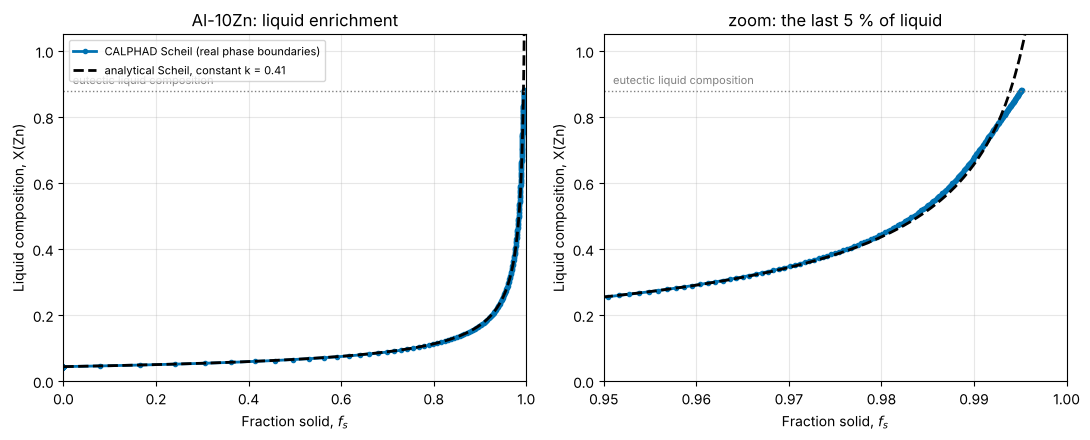

Eutectic fraction, analytic Scheil equation : 0.0061
Eutectic fraction, CALPHAD Scheil           : 0.0049


In [8]:
label = "Al-10Zn"
sch = results[label]["scheil"]
fs   = np.array(sch.fraction_solid)
x_l  = np.array(sch.x_liquid["ZN"])
x_s  = np.array(sch.phase_compositions["FCC_A1"]["ZN"])

first = np.argmax(np.isfinite(x_s))      # index of the first step with FCC
k = x_s[first] / x_l[first]              # partition coefficient at the liquidus
C0 = float(wt_to_x_zn(ALLOYS[label]))
print(f"Partition coefficient at the liquidus: k = {k:.3f}  (k < 1: Zn is rejected into the liquid)")

fs_line = np.linspace(0, 0.9999, 2000)
C_L_analytic = C0 * (1 - fs_line) ** (k - 1)
ok = np.isfinite(x_l)

# Two panels: the whole solidification, and a zoom on the last few percent
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, xlim in zip(axes, [(0, 1), (0.95, 1)]):
    ax.plot(fs[ok], x_l[ok], "-o", ms=3, lw=2, color=COLORS[0], label="CALPHAD Scheil (real phase boundaries)")
    ax.plot(fs_line, C_L_analytic, "--", lw=2, color="k", label=f"analytical Scheil, constant k = {k:.2f}")
    ax.axhline(0.88, color="grey", ls=":", lw=1)
    ax.text(xlim[0] + 0.02 * (xlim[1] - xlim[0]), 0.90, "eutectic liquid composition", color="grey", fontsize=8)
    ax.set_xlim(*xlim)
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("Fraction solid, $f_s$")
    ax.set_ylabel("Liquid composition, X(Zn)")
    ax.grid(alpha=0.3)
axes[0].set_title(f"{label}: liquid enrichment")
axes[1].set_title("zoom: the last 5 % of liquid")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

# Analytic estimate of the eutectic fraction: the liquid left when C_L reaches
# the eutectic composition, from C_eut = C0 (1 - fs)^(k-1)  ->  f_L = (C_eut/C0)^(1/(k-1))
f_eut_analytic = (0.88 / C0) ** (1 / (k - 1))
f_eut_calphad = summary.loc[label, "Scheil eutectic fraction"]
print(f"Eutectic fraction, analytic Scheil equation : {f_eut_analytic:.4f}")
print(f"Eutectic fraction, CALPHAD Scheil           : {f_eut_calphad:.4f}")

**What this shows:** for Al–10Zn the textbook formula with a single *k* is remarkably good — the Al-rich liquidus and solidus of Al–Zn happen to have a nearly constant ratio, so this is a "friendly" system. The differences appear only at the very end (right panel): the analytical formula doesn't know the eutectic exists and lets C<sub>L</sub> climb without limit as f<sub>s</sub> → 1, whereas the CALPHAD calculation stops at the eutectic composition and converts the remaining liquid into FCC + HCP. The predicted eutectic fractions printed above are therefore similar, but not identical.

For most engineering alloys you are *not* this lucky: *k* varies strongly with temperature, there are several solutes that interact with each other, and several solid phases can form in sequence. No closed-form equation handles that, which is why **CALPHAD-based Scheil calculations replaced the hand formula in industrial practice**.

---
---

# ✋✋✋ YOUR LAB DATA GOES HERE ✋✋✋

<div style="border: 3px solid #D55E00; padding: 12px; border-radius: 6px;">

**This section is reserved for comparing the CALPHAD predictions above with your own solidification-lab measurements.**
Nothing in this section contains real data yet. Until you add files, every cell below simply prints *"no data found"* and moves on, so the notebook always runs end to end.

</div>

### What kinds of data are supported?

Put your files in the repository's `data/` folder. Blank templates with the exact column names are in `data/templates/` (see `data/README.md`). Use whichever of the three formats you have — you don't need all of them.

| Format | File to create | Columns | Typical source |
|---|---|---|---|
| **A. Arrest temperatures** | `data/my_arrest_temperatures.csv` | `alloy_label, wt_pct_zn, liquidus_C, final_arrest_C, notes` | Reading the thermal arrests off a cooling curve by eye |
| **B. Fraction solid vs. T** | `data/my_fraction_solid.csv` | `alloy_label, wt_pct_zn, temperature_C, fraction_solid` | DSC, or a cooling curve already processed elsewhere |
| **C. Raw cooling curves** | one CSV per run in `data/cooling_curves/` | `time_s, temperature_C` | Thermocouple logger; this notebook converts it to f<sub>s</sub>(T) with Newtonian thermal analysis |

**Units:** temperature in °C, time in s, composition in **wt.% Zn** (the notebook converts). If your alloy was analysed (e.g. by XRF/ICP), use the *measured* composition, not the nominal one.

### Step 1 — tell the notebook where your files are

In [9]:
# ==== ✏️ EDIT THIS CELL ======================================================
LAB_ARRESTS_FILE = "../data/my_arrest_temperatures.csv"   # format A
LAB_FS_FILE      = "../data/my_fraction_solid.csv"        # format B

# Format C: one entry per raw cooling-curve file.
#   "label": {"file": path, "wt_pct_zn": composition,
#             "t_start": time (s) where solidification starts (liquidus arrest),
#             "t_end":   time (s) where solidification ends (after the last arrest)}
# Leave t_start / t_end as None the first time: the notebook will plot the curve
# and its derivative so you can pick them, then come back and fill them in.
COOLING_CURVES = {
    # "Al-10Zn run 1": {"file": "../data/cooling_curves/Al10Zn_run1.csv",
    #                   "wt_pct_zn": 10.0, "t_start": None, "t_end": None},
}
# ============================================================================

def load_csv_if_present(path):
    # Return a DataFrame, or None if the file doesn't exist / has no data rows.
    if not os.path.exists(path):
        print(f"ℹ️  No file at {path} yet — skipping. (Template: data/templates/)")
        return None
    df = pd.read_csv(path, comment="#", skipinitialspace=True).dropna(how="all")
    if df.empty:
        print(f"ℹ️  {path} has no data rows yet — skipping.")
        return None
    print(f"✅ Loaded {len(df)} rows from {path}")
    return df

lab_arrests = load_csv_if_present(LAB_ARRESTS_FILE)
lab_fs      = load_csv_if_present(LAB_FS_FILE)

ℹ️  No file at ../data/my_arrest_temperatures.csv yet — skipping. (Template: data/templates/)
ℹ️  No file at ../data/my_fraction_solid.csv yet — skipping. (Template: data/templates/)


### Step 2 (format A) — measured arrest temperatures vs. CALPHAD

For each measured alloy we (re)compute the predictions at *its* composition and put them side by side. Things to look for:

* **Liquidus:** measured vs. calculated should agree within a few K if the thermocouple is calibrated. A lower measured value often means **undercooling** before nucleation (look for recalescence — a small temperature rise — on the cooling curve).
* **Final arrest:** if you see an arrest near **381 °C** in an alloy that is single-phase FCC at equilibrium, you've measured **non-equilibrium eutectic** — direct evidence that solidification was Scheil-like.

In [10]:
if lab_arrests is not None:
    rows = []
    for _, m in lab_arrests.iterrows():
        calc = summarise(m["alloy_label"], float(m["wt_pct_zn"]))
        rows.append({
            "alloy": m["alloy_label"], "wt.% Zn": m["wt_pct_zn"],
            "liquidus meas. (°C)": m["liquidus_C"],
            "liquidus calc. (°C)": calc["liquidus (°C)"],
            "Δ liquidus (K)": round(m["liquidus_C"] - calc["liquidus (°C)"], 1),
            "final arrest meas. (°C)": m["final_arrest_C"],
            "eq. solidus calc. (°C)": calc["eq. solidus (°C)"],
            "Scheil end calc. (°C)": calc["Scheil end (°C)"],
        })
    comparison = pd.DataFrame(rows).set_index("alloy")
    display(comparison)

### Step 3 (format C, optional) — turn raw cooling curves into f<sub>s</sub>(T)

**Newtonian thermal analysis (NTA)** in one paragraph: a small sample cooling in still air loses heat at a rate roughly proportional to its temperature excess. While it solidifies, latent heat is released, so the sample cools *more slowly* than it "should". If we estimate the cooling rate the sample *would* have had with no solidification (the **zero curve** or *baseline*), then the extra area between the actual dT/dt and the baseline is proportional to the latent heat released so far — i.e. to f<sub>s</sub>.

**How we build the zero curve:** Newton's law of cooling says that without any reaction, dT/dt ≈ −*h*·(T − T<sub>ambient</sub>), i.e. a **straight line when dT/dt is plotted against T**. So we take the cooling-curve points just *before* solidification starts (pure liquid) and just *after* it ends (fully solid), fit dT/dt = *a* + *b*·T through them, and use that line as the baseline inside the solidification window. (We tested this on a synthetic cooling curve generated from the Scheil result itself: it recovered f<sub>s</sub>(T) to within ≈0.01.)

This is still an approximation — heat capacity and heat-transfer coefficient differ between liquid and solid, and the thermocouple has a finite response time. More sophisticated methods exist (Fourier thermal analysis, two-thermocouple methods), so treat the result as semi-quantitative and **say so in your report**.

**Tip:** record the cooling curve from well above the liquidus to well below the final arrest — the baseline fit needs reaction-free data on both sides.

1. Run the next cell once with `t_start`/`t_end` = `None` → look at the plots → pick times where dT/dt departs from / returns to the smooth no-reaction trend.
2. Fill those times into `COOLING_CURVES` above and re-run.

In [11]:
def smooth(y, window=11):
    # Simple moving-average smoothing (window must be odd). Thermocouple data is
    # noisy and differentiating noise makes it much worse, so we smooth first.
    window = max(3, int(window) | 1)
    kernel = np.ones(window) / window
    ypad = np.pad(y, window // 2, mode="edge")
    return np.convolve(ypad, kernel, mode="valid")

def newtonian_fraction_solid(time_s, temp_C, t_start, t_end, window=11, fit_span_s=None):
    # Convert a cooling curve into (T, f_s) between t_start and t_end.
    #   window     : smoothing window (number of points) before differentiating
    #   fit_span_s : how many seconds before t_start and after t_end are used to
    #                fit the Newtonian zero curve (default: 10 % of the
    #                solidification time on each side)
    t = np.asarray(time_s, dtype=float)
    T = smooth(np.asarray(temp_C, dtype=float), window)
    dTdt = np.gradient(T, t)                         # cooling rate (negative)

    # --- 1. Fit the zero curve dT/dt = a + b*T on reaction-free data --------
    span = fit_span_s if fit_span_s is not None else 0.10 * (t_end - t_start)
    fit = ((t >= t_start - span) & (t < t_start)) | ((t > t_end) & (t <= t_end + span))
    if fit.sum() < 6:
        raise ValueError("Not enough data before t_start / after t_end to fit the "
                         "zero curve: record longer, or increase fit_span_s.")
    b, a = np.polyfit(T[fit], dTdt[fit], 1)          # slope b, intercept a

    # --- 2. Latent-heat signal inside the solidification window -------------
    sel = (t >= t_start) & (t <= t_end)
    t_s, T_s = t[sel], T[sel]
    excess = dTdt[sel] - (a + b * T_s)               # >0: cooling slower than baseline

    # --- 3. Integrate over time and normalise so that f_s goes 0 -> 1 -------
    cum = np.concatenate([[0], np.cumsum(0.5 * (excess[1:] + excess[:-1]) * np.diff(t_s))])
    fs = np.clip(cum / cum[-1], 0, 1)
    return T_s, fs

lab_cooling_fs = {}   # label -> (wt%, T_C array, f_s array)

if not COOLING_CURVES:
    print("ℹ️  No cooling curves listed in COOLING_CURVES yet — skipping.")

for label, cfg in COOLING_CURVES.items():
    raw = pd.read_csv(cfg["file"], comment="#", skipinitialspace=True).dropna()
    t, T = raw["time_s"].to_numpy(), raw["temperature_C"].to_numpy()

    fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
    a1.plot(t, T, lw=1); a1.set_ylabel("T (°C)"); a1.set_title(f"{label}: cooling curve")
    a1.axhline(380.9, color="grey", ls=":", lw=1)
    a2.plot(t, np.gradient(smooth(T), t), lw=1); a2.set_ylabel("dT/dt (K/s)"); a2.set_xlabel("time (s)")
    for a in (a1, a2):
        a.grid(alpha=0.3)
        for key in ("t_start", "t_end"):
            if cfg.get(key) is not None:
                a.axvline(cfg[key], color="r", ls="--", lw=1)
    plt.show()

    if cfg.get("t_start") is None or cfg.get("t_end") is None:
        print(f"👉 {label}: choose t_start / t_end from the plots, add them to COOLING_CURVES, re-run.")
        continue

    T_fs, fs = newtonian_fraction_solid(t, T, cfg["t_start"], cfg["t_end"])
    lab_cooling_fs[label] = (cfg["wt_pct_zn"], T_fs, fs)
    print(f"✅ {label}: converted to f_s(T) between {T_fs[0]:.1f} and {T_fs[-1]:.1f} °C")

ℹ️  No cooling curves listed in COOLING_CURVES yet — skipping.


### Step 4 — overlay measurements on the predicted f<sub>s</sub>(T) curves

Each measured alloy is plotted with its own equilibrium and Scheil predictions (computed at the measured composition). **If your data lies between the two curves, closer to Scheil, that's the expected behaviour for a normal casting.**

In [12]:
# Gather every measured data set: label -> (wt%, T_C, f_s, marker)
measured = {}
if lab_fs is not None:
    for lab_label, grp in lab_fs.groupby("alloy_label"):
        grp = grp.sort_values("temperature_C", ascending=False)
        measured[f"{lab_label} (f_s data)"] = (float(grp["wt_pct_zn"].iloc[0]),
                                               grp["temperature_C"].to_numpy(),
                                               grp["fraction_solid"].to_numpy(), "o")
for lab_label, (wt, T_fs, fs) in lab_cooling_fs.items():
    measured[f"{lab_label} (cooling curve, NTA)"] = (wt, T_fs, fs, ".")

if not measured:
    print("ℹ️  No measured f_s data yet — add format B and/or C data above to see the comparison plot.")
else:
    fig, ax = plt.subplots(figsize=(8, 6))
    for i, (name, (wt, T_meas, fs_meas, mk)) in enumerate(measured.items()):
        c = COLORS[i % len(COLORS)]
        r = run_solidification(wt)
        ax.plot(r["equilibrium"].fraction_solid, K_to_C(r["equilibrium"].temperatures),
                "-", color=c, lw=1.5, label=f"{wt:g} wt.% Zn equilibrium (calc.)")
        ax.plot(r["scheil"].fraction_solid, K_to_C(r["scheil"].temperatures),
                "--", color=c, lw=1.5, label=f"{wt:g} wt.% Zn Scheil (calc.)")
        ax.plot(fs_meas, T_meas, mk, color=c, ms=5, mec="k", mew=0.5, label=f"{name} (measured)")
    ax.axhline(380.9, color="grey", lw=0.8, ls=":")
    ax.set_xlabel("Fraction solid, $f_s$")
    ax.set_ylabel("Temperature (°C)")
    ax.set_xlim(0, 1)
    ax.set_title("CALPHAD predictions vs. lab measurements")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig("../figures/lab_vs_calphad.png", dpi=200)
    plt.show()

ℹ️  No measured f_s data yet — add format B and/or C data above to see the comparison plot.


### Step 5 — questions to answer in your lab report

1. Does your measured liquidus agree with CALPHAD within your thermocouple uncertainty? If not, is there evidence of undercooling/recalescence?
2. Do you see an arrest at ≈381 °C? What does that tell you about diffusion in the solid during your experiment?
3. Where does your f<sub>s</sub>(T) curve sit relative to the equilibrium and Scheil limits? Estimate your cooling rate (K/s) from the cooling curve — would a faster or slower cooling rate move you toward Scheil?
4. If you have micrographs: is there interdendritic eutectic? Does its area fraction roughly match the "Scheil eutectic fraction" in the summary table (Section 5)? (Remember to convert: the table is in mole-based phase fraction; area fraction ≈ volume fraction.)
5. If you have EDS line scans across dendrites: compare them with the coring plot in Section 7.
6. List the error sources: thermocouple calibration & response time, composition uncertainty, oxide/impurities (Fe, Si), the NTA baseline assumption, and limitations of the thermodynamic database itself.

<div style="border: 3px solid #D55E00; padding: 6px; border-radius: 6px;"><b>✋ End of the lab-data section.</b></div>

---

## 8. Summary

* **Equilibrium (lever rule)** and **Scheil–Gulliver** bound real solidification behaviour: full vs. zero diffusion in the solid.
* For Al-rich Al–Zn alloys the equilibrium diagram says single-phase FCC, but **Scheil predicts a much wider freezing range and some interdendritic eutectic at 380.9 °C** — because rejected Zn accumulates in the last liquid.
* The frozen-in composition gradient (**coring**) is microsegregation. It affects heat-treatment windows (incipient melting), corrosion, mechanical properties and hot tearing.
* With CALPHAD these predictions take seconds and work for real multicomponent alloys — which is why it's a routine tool in alloy design and casting/AM process development.

## References

1. S. an Mey, "Reevaluation of the Al–Zn system", *Z. Metallkd.* 84 (1993) 451–455. (TDB: T. Abe, K. Hashimoto, Y. Sawada, NIMS CPDDB.)
2. R. Otis, Z.-K. Liu, "pycalphad: CALPHAD-based Computational Thermodynamics in Python", *J. Open Res. Softw.* 5 (2017) 1. doi:10.5334/jors.140
3. B. Bocklund, L. D. Bobbitt, R. A. Otis, A. M. Beese, Z.-K. Liu, "Experimental validation of Scheil–Gulliver simulations for gradient path planning in additively manufactured functionally graded materials", *Mater. Today Commun.* 25 (2020) 101515. doi:10.1016/j.mtcomm.2020.101515
4. E. Scheil, "Bemerkungen zur Schichtkristallbildung", *Z. Metallkd.* 34 (1942) 70–72.
5. D. A. Porter, K. E. Easterling, M. Y. Sherif, *Phase Transformations in Metals and Alloys*, 3rd ed., CRC Press (2009), Ch. 4 (solidification of alloys).
6. H. L. Lukas, S. G. Fries, B. Sundman, *Computational Thermodynamics: The Calphad Method*, Cambridge University Press (2007).